# Native Prefix別の外側IPv4プロトコル構成

MAWI Samplepoint-F、2026-04-08 14:00以上14:15未満 JST。集計済みCSV/JSONだけを読み、PCAPの読込・解析・Prefix選定を行いません。

**研究上の定義**：native CIDRをそのまま使用し、`src in Prefix OR dst in Prefix` で所属させます。同一Prefix内では一度だけ計上し、異なるPrefix間では重複し得ます。外側IPv4 Protocolを使用し、GRE/ESPの内部展開・フラグメント再構成・scan除外は行いません。判定不能は非TCP/UDPとは別分類です。各図の分母はその行の全IPv4パケット、または対応するバイト総量（判定不能を含む）。主バイト指標はPCAP `orig_len`、IPバイトを選んだ場合は取得可能なIP長の合計です。分母0の比率は未定義として表示します。

選定元や18件の真正性が未検証ならmanifestに保留と記録されます。合成fixtureの実行を実測結果と解釈しないでください。


In [1]:
from pathlib import Path

RESULTS_DIR = None  # Path("/path/to/results/202604081400/prefix_protocol_distribution")
DATA_LABEL = None  # 合成データでは必ず "Synthetic fixture (not MAWI measurements)" 等を指定
BYTE_METRIC = "original_frame_bytes"  # または "ip_packet_bytes"（取得可能なIP長）
DISPLAY_PROTOCOLS = (6, 17, 1, 47, 50, 4, 41)
OTHERS_THRESHOLD_PCT = 1.0  # いずれかの行のパケット比・バイト比がこの値以上なら個別表示。Noneは指定番号のみ
HEATMAP_METRIC = "packet_count"  # "packet_count" または BYTE_METRIC
DETAIL_TOP_N = 5
FIGSIZE = (12, 6)


## 読込・整合性確認・総量

Prefixの順序は`selected_prefixes.csv`の保存順です。Overall IPv4を先頭に置き、図の間で並べ替えません。`selected_union`は単純合算ではなく、同一パケットを一度だけ数えた集合です。総量表には参考として表示します。


In [2]:
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

%matplotlib inline

if BYTE_METRIC not in {"original_frame_bytes", "ip_packet_bytes"}:
    raise ValueError("Unsupported BYTE_METRIC")
if HEATMAP_METRIC not in {"packet_count", BYTE_METRIC}:
    raise ValueError("HEATMAP_METRIC must be packet_count or BYTE_METRIC")
if DETAIL_TOP_N < 1 or (OTHERS_THRESHOLD_PCT is not None and not 0 <= OTHERS_THRESHOLD_PCT <= 100):
    raise ValueError("Invalid display settings")
root = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
results_dir = Path(RESULTS_DIR or root / "results/202604081400/prefix_protocol_distribution").expanduser().resolve()
files = ("selected_prefixes.csv", "prefix_protocol_counts.csv", "prefix_summary.csv",
         "prefix_protocol_timeseries_60s.csv", "summary.json", "manifest.json")
missing = [name for name in files if not (results_dir / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing aggregate files: {missing}; run CLI with --prefixes first")
summary = json.loads((results_dir / "summary.json").read_text())
manifest = json.loads((results_dir / "manifest.json").read_text())
if summary["schema_version"] != 2 or manifest["schema_version"] != 2:
    raise ValueError("Expected prefix output schema_version=2")
if summary["analysis_window"] != manifest["analysis_window"]:
    raise ValueError("Analysis windows differ")
for name in files[:4]:
    if hashlib.sha256((results_dir / name).read_bytes()).hexdigest() != manifest["output_sha256"][name]:
        raise ValueError(f"CSV checksum mismatch: {name}")
selected = pd.read_csv(results_dir / "selected_prefixes.csv", dtype={"prefix": str})
counts = pd.read_csv(results_dir / "prefix_protocol_counts.csv", dtype={"scope": str, "protocol_number": "Int64"})
timeseries = pd.read_csv(results_dir / "prefix_protocol_timeseries_60s.csv", dtype={"scope": str, "protocol_number": "Int64"})
totals = pd.read_csv(results_dir / "prefix_summary.csv", dtype={"scope": str}).set_index("scope")
prefix_order = selected["prefix"].tolist()
if (selected["prefix_order"].tolist() != list(range(1, len(selected) + 1))
        or selected["prefix"].duplicated().any() or not selected["analysis_scope"].eq("native").all()
        or prefix_order != manifest["configuration"]["content"]["prefixes"]):
    raise ValueError("Selected native prefix order differs from manifest")
scope_order = ["overall_ipv4", *prefix_order]
all_scopes = [*scope_order, "selected_union"]
if summary["scope_order"] != all_scopes or totals.index.tolist() != all_scopes:
    raise ValueError("Population order differs")
COUNTERS = ["packet_count", "original_frame_bytes", "ip_packet_bytes", "ip_length_known_packets",
            "ip_length_unavailable_packets", "fragment_packets", "truncated_capture_packets",
            "invalid_or_missing_header_packets"]
for table in (counts, timeseries):
    if set(table["scope"]) - set(all_scopes) or (table[COUNTERS] < 0).any().any():
        raise ValueError("Unexpected scopes or negative counters")
for name in all_scopes:
    for metric in COUNTERS:
        expected = summary["populations"][name][metric]
        if (totals.loc[name, metric] != expected
                or counts.loc[counts["scope"].eq(name), metric].sum() != expected
                or timeseries.loc[timeseries["scope"].eq(name), metric].sum() != expected):
            raise ValueError(f"Population counters differ: {name}, {metric}")
counts["protocol"] = counts["protocol_number"].astype("string").fillna("Indeterminate")
timeseries["protocol"] = timeseries["protocol_number"].astype("string").fillna("Indeterminate")
if counts.duplicated(["scope", "protocol"]).any() or timeseries.duplicated(["scope", "protocol", "interval_start_jst"]).any():
    raise ValueError("Duplicate protocol rows")
if not counts.empty:
    rolled = timeseries.groupby(["scope", "protocol"])[COUNTERS].sum().sort_index()
    direct = counts.set_index(["scope", "protocol"])[COUNTERS].sort_index()
    pd.testing.assert_frame_equal(rolled, direct, check_dtype=False)
    expected_bins = {(row["interval_start_jst"], row["interval_end_jst"]) for row in summary["intervals"]}
    for _, group in timeseries.groupby(["scope", "protocol"]):
        if set(zip(group["interval_start_jst"], group["interval_end_jst"])) != expected_bins:
            raise ValueError("Time bins differ")
window = summary["analysis_window"]
if window["interval_seconds"] != 60 or window["boundary"] != "[start, end)":
    raise ValueError("Expected half-open 60-second intervals")
dataset_caption = DATA_LABEL or f"{manifest['dataset']['name']} / {manifest['dataset']['samplepoint']}"
start_label = pd.Timestamp(window["start_jst"]).strftime("%Y-%m-%d %H:%M:%S")
end_label = pd.Timestamp(window["end_jst"]).strftime("%Y-%m-%d %H:%M:%S")
caption = f"{dataset_caption} | {start_label} to {end_label} JST"
byte_label = {"original_frame_bytes": "PCAP orig_len bytes", "ip_packet_bytes": "known IP packet bytes"}[BYTE_METRIC]
labels = {"overall_ipv4": "Overall IPv4", **{p: p for p in prefix_order}, "selected_union": "Selected union"}
print(caption)
print("Historical selection:", manifest["prefix_selection"]["historical_selection_verification"])
print("Source input identity:", manifest["prefix_selection"]["input_identity"])
display(totals.loc[all_scopes, COUNTERS].rename(index=labels))
display(pd.DataFrame([manifest["prefix_selection"]]))


MAWI Traffic Archive / Samplepoint-F | 2026-04-08 14:00:00 to 2026-04-08 14:15:00 JST
Historical selection: pending_external_audit
Source input identity: matching_file_bytes


,packet_count,original_frame_bytes,ip_packet_bytes,ip_length_known_packets,ip_length_unavailable_packets,fragment_packets,truncated_capture_packets,invalid_or_missing_header_packets
scope,,,,,,,,
Overall IPv4,246310569,237882598163,233965033225,246310569,0,927532,188079289,0
131.142.206.160/32,2033375,6173585456,6145118167,2033375,0,0,2026532,0
131.142.238.168/32,3596902,4981675603,4931317877,3596902,0,0,3540442,0
133.132.116.53/32,5403781,4226378261,4150693816,5403781,0,0,4147681,0
142.11.234.5/32,1074399,5672641333,5657599747,1074399,0,0,738301,0
150.217.137.141/32,7250482,14697799246,14596291990,7250482,0,0,3786892,0
150.217.140.38/32,12845778,8716235198,8536373242,12845778,0,90963,12845725,0
151.34.117.44/32,956897,4065394304,4051997746,956897,0,0,942890,0
157.53.116.0/28,6642922,12119415947,12026308962,6642922,0,2,5572847,0


,config,historical_selection_verification,input_identity,manifest,membership_csv,native_origin,order,overlaps,prefixes_csv
0,None,pending_external_audit,matching_file_bytes,{'content': {'artifacts': {'aguri_candidates':...,{'path': '/home/s-sakai/mawi-global-analysis/r...,declared_by_external_ledger_provider,selected CSV row order; historical Notebook or...,[],{'path': '/home/s-sakai/mawi-global-analysis/r...


In [3]:
# 集計値を変更せず、表示用の行列だけを作る。
MEASURES = ["packet_count", "original_frame_bytes", "ip_packet_bytes"]
protocols = sorted((p for p in counts["protocol"].unique() if p != "Indeterminate"), key=int)
if "Indeterminate" in set(counts["protocol"]):
    protocols.append("Indeterminate")

def values(metric, frame=counts):
    matrix = frame.pivot_table(index="scope", columns="protocol", values=metric, aggfunc="sum", fill_value=0)
    return matrix.reindex(index=scope_order, columns=protocols, fill_value=0).astype(float)

# 分母は各Prefixの全IPv4（番号不明も含む）であり、表示する番号だけの和ではない。
def percent(matrix, metric):
    denominator = totals.loc[matrix.index, metric].replace(0, np.nan)
    return matrix.div(denominator, axis=0) * 100

keep = {str(number) for number in DISPLAY_PROTOCOLS} | {"Indeterminate"}
if OTHERS_THRESHOLD_PCT is not None:
    for metric in ("packet_count", BYTE_METRIC):
        shares = percent(values(metric), metric)
        keep.update(shares.columns[shares.ge(OTHERS_THRESHOLD_PCT).any()])
display_group = {p: p if p in keep else "Others" for p in protocols}
plot_order = [p for p in protocols if p in keep]
if "Others" in display_group.values():
    plot_order.append("Others")
fixed = {"6": "#28658E", "17": "#E17832", "1": "#398655", "47": "#B7464E",
         "50": "#93714F", "4": "#9469BD", "41": "#AF8C37",
         "Indeterminate": "#59636B", "Others": "#ADB5C2"}
palette = plt.get_cmap("tab20")
colors = {p: fixed.get(p, palette(int(p) % 20) if p.isdecimal() else "#59636B") for p in plot_order}
protocol_names = counts.drop_duplicates("protocol").set_index("protocol")["protocol_name"].to_dict()
protocol_labels = {p: f"{p}: {protocol_names[p]}" if p.isdecimal() else p for p in plot_order}

def shown_values(metric, frame=counts):
    raw = values(metric, frame)
    shown = pd.DataFrame(0.0, index=scope_order, columns=plot_order)
    for protocol in protocols:
        shown[display_group[protocol]] += raw[protocol]
    return shown

for metric in MEASURES:
    np.testing.assert_allclose(shown_values(metric).sum(axis=1), totals.loc[scope_order, metric])

def stacked(ax, shares, metric):
    left = np.zeros(len(shares))
    for protocol in shares.columns:
        heights = shares[protocol].fillna(0).to_numpy()
        ax.barh(range(len(shares)), heights, left=left, color=colors[protocol], label=protocol_labels[protocol])
        left += heights
    ax.set_yticks(range(len(shares)), [labels[p] for p in shares.index])
    for index, scope in enumerate(shares.index):
        if totals.loc[scope, metric] == 0:
            ax.text(1, index, "Undefined (zero denominator)", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.set_xlabel(f"Share of all IPv4 {('packets' if metric == 'packet_count' else byte_label)} in each row (%)")
    if len(shares.columns):
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

def finish(fig, title):
    fig.suptitle(f"{title}\n{caption}", fontsize=10)
    plt.show()
    plt.close(fig)


## 1・2：Overall IPv4と各native Prefixの構成比

同じ順序・表示分類・色で比較します。Othersは表示時だけの集約です。判定不能は常に独立表示します。


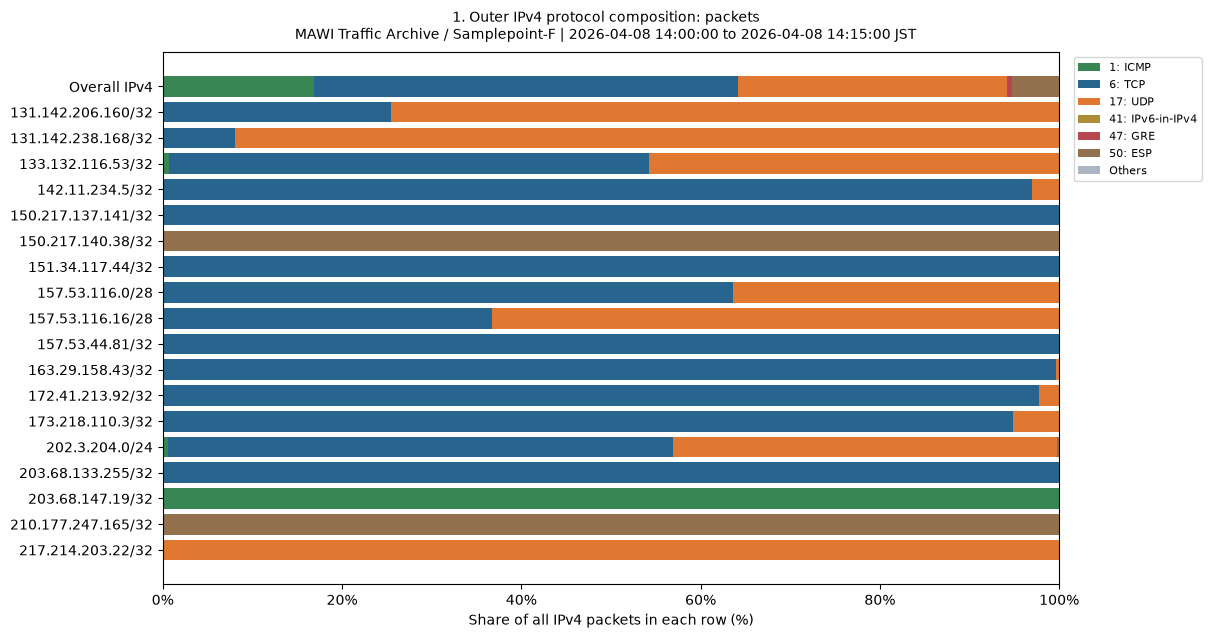

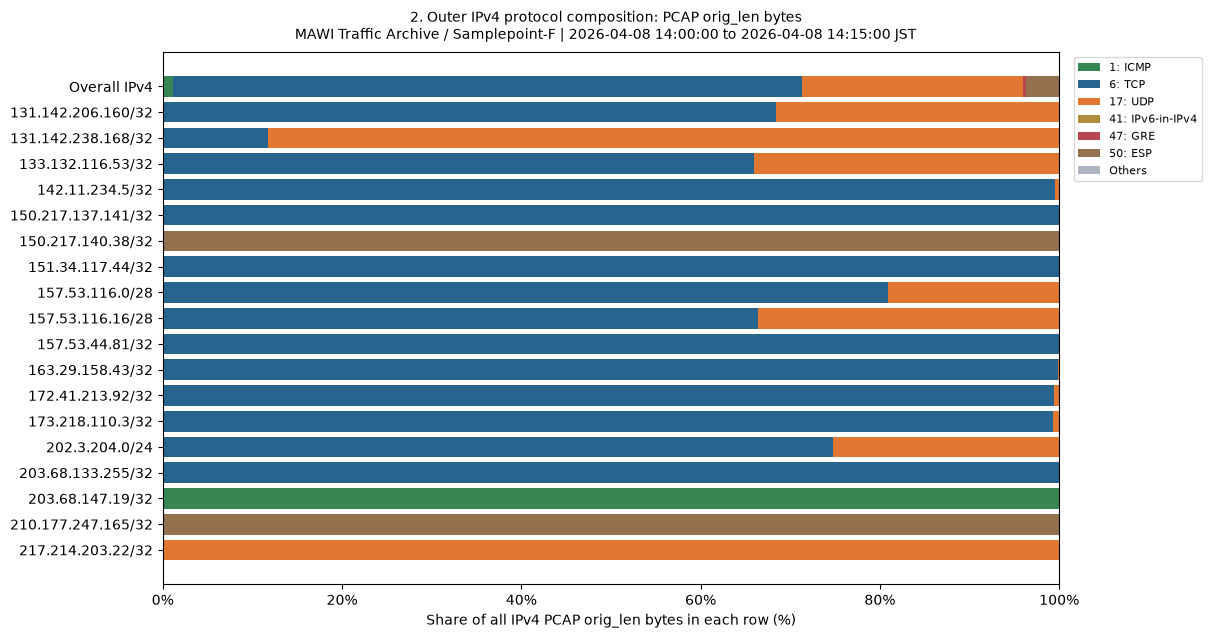

In [4]:
packet_shares = percent(shown_values("packet_count"), "packet_count")
byte_shares = percent(shown_values(BYTE_METRIC), BYTE_METRIC)
for metric, shares, title in (("packet_count", packet_shares, "1. Outer IPv4 protocol composition: packets"),
                              (BYTE_METRIC, byte_shares, f"2. Outer IPv4 protocol composition: {byte_label}")):
    fig, ax = plt.subplots(figsize=(FIGSIZE[0], max(FIGSIZE[1], len(scope_order) * .33)), layout="constrained")
    stacked(ax, shares, metric)
    finish(fig, title)


## 3：非TCP/UDP割合とOverall IPv4との差分

非TCP/UDPは番号が6・17以外と確認できたものです。分母には判定不能も含みます。ラベルに割合（%）、横軸にOverallとの差（パーセントポイント：pp）を示します。


,packet_count_pct,packet_count_delta_pp,original_frame_bytes_pct,original_frame_bytes_delta_pp
131.142.206.160/32,0.020704,-22.712518,0.000590,-5.255887
131.142.238.168/32,0.024744,-22.708479,0.002124,-5.254353
133.132.116.53/32,0.663554,-22.069669,0.113708,-5.142769
142.11.234.5/32,0.007632,-22.725590,0.000163,-5.256314
150.217.137.141/32,0.114213,-22.619010,0.005437,-5.251040
150.217.140.38/32,99.999478,77.266256,99.999939,94.743462
151.34.117.44/32,0.000000,-22.733223,0.000000,-5.256477
157.53.116.0/28,0.074410,-22.658813,0.007614,-5.248862
157.53.116.16/28,0.024661,-22.708562,0.001745,-5.254732
157.53.44.81/32,0.002302,-22.730921,0.000060,-5.256417


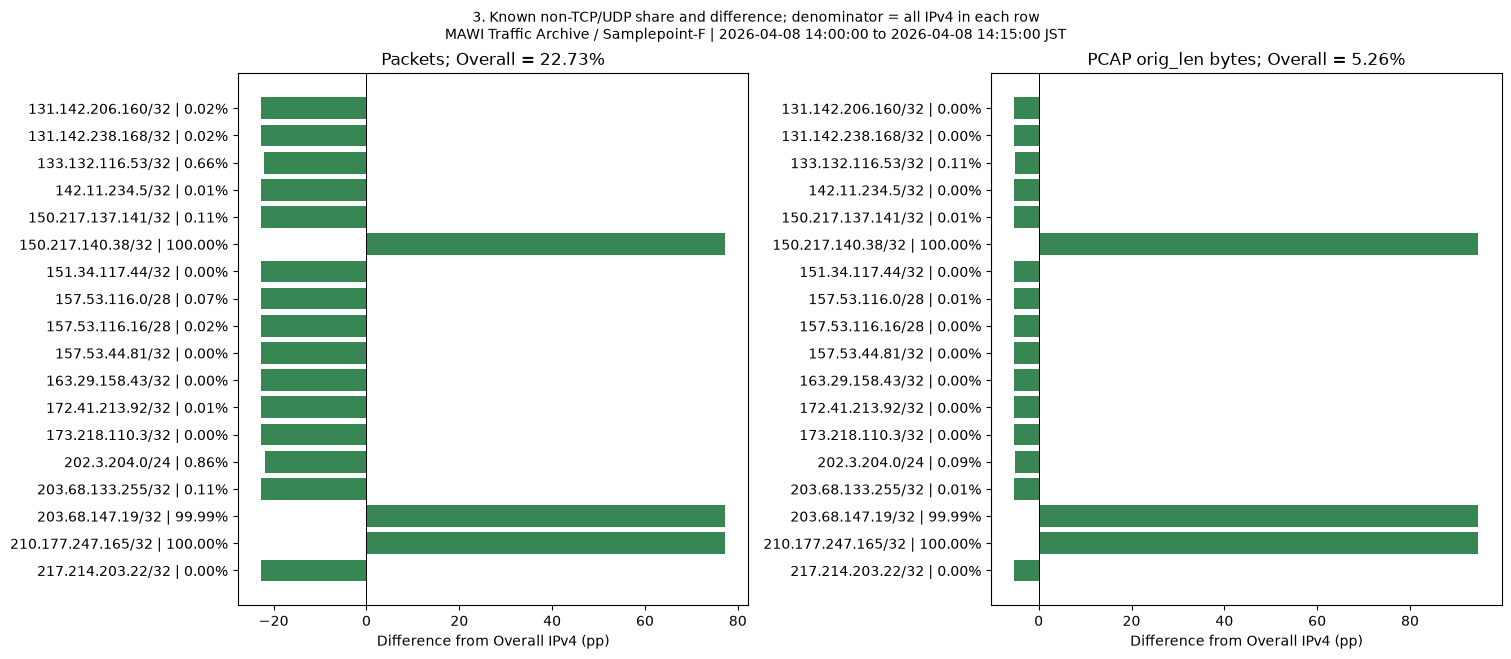

In [5]:
non_tcp = counts.loc[counts["protocol_number"].notna() & ~counts["protocol_number"].isin([6, 17])].copy()
non_tcp_ratios = {}
comparison = pd.DataFrame(index=prefix_order)
for metric in ("packet_count", BYTE_METRIC):
    numerator = non_tcp.groupby("scope")[metric].sum().reindex(scope_order, fill_value=0)
    share = numerator.div(totals.loc[scope_order, metric].replace(0, np.nan)) * 100
    non_tcp_ratios[metric] = share
    comparison[f"{metric}_pct"] = share.reindex(prefix_order)
    comparison[f"{metric}_delta_pp"] = share.reindex(prefix_order) - share.loc["overall_ipv4"]
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(FIGSIZE[0] + 3, max(FIGSIZE[1], len(prefix_order) * .36)), layout="constrained")
for ax, metric, title in zip(axes, ("packet_count", BYTE_METRIC), ("Packets", byte_label)):
    shares = comparison[f"{metric}_pct"]
    deltas = comparison[f"{metric}_delta_pp"]
    ax.barh(range(len(prefix_order)), deltas.fillna(0), color="#398655")
    ax.set_yticks(range(len(prefix_order)), [f"{p} | {v:.2f}%" if pd.notna(v) else f"{p} | Undefined" for p, v in shares.items()])
    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=.7)
    ax.set_xlabel("Difference from Overall IPv4 (pp)")
    baseline = non_tcp_ratios[metric].loc["overall_ipv4"]
    ax.set_title(f"{title}; Overall = {baseline:.2f}%")
finish(fig, "3. Known non-TCP/UDP share and difference; denominator = all IPv4 in each row")


## 4：Prefix × プロトコルの構成比

`HEATMAP_METRIC`でパケット数または選択バイト指標を指定します。色の濃さは構成比（%）を表し、列ラベルの色は他図と同じプロトコル色です。白色は分母0で未定義です。


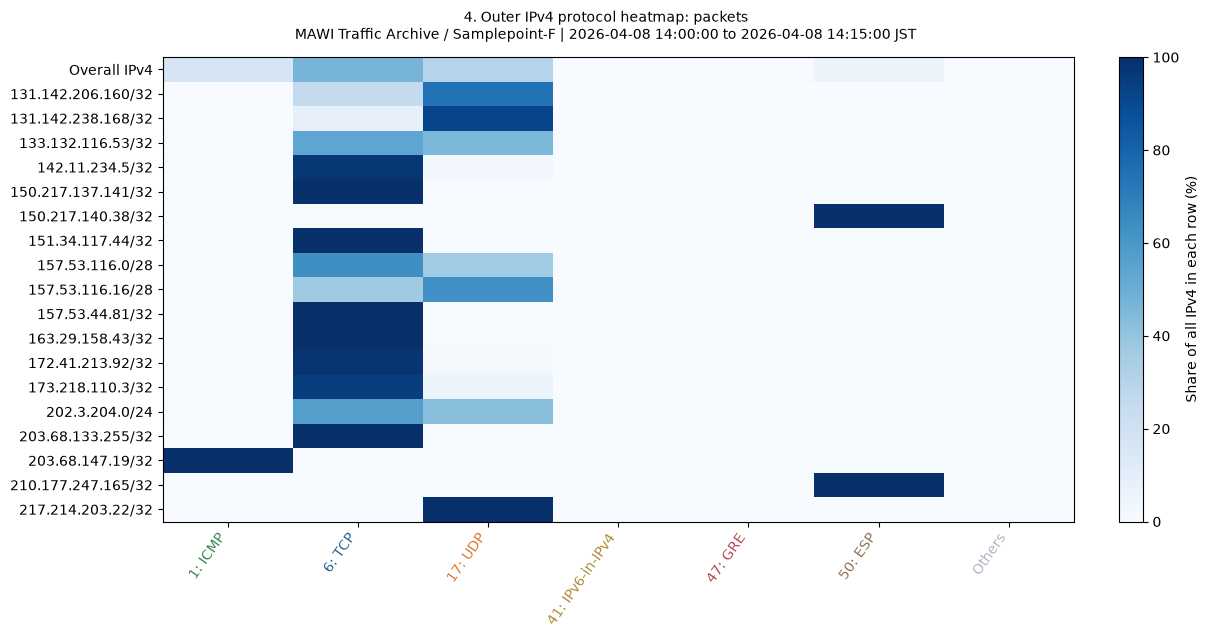

In [6]:
heatmap_shares = percent(shown_values(HEATMAP_METRIC), HEATMAP_METRIC)
fig, ax = plt.subplots(figsize=(FIGSIZE[0], max(FIGSIZE[1], len(scope_order) * .33)), layout="constrained")
if heatmap_shares.shape[1]:
    image = ax.imshow(np.ma.masked_invalid(heatmap_shares.to_numpy()), aspect="auto", vmin=0, vmax=100, cmap="Blues")
    fig.colorbar(image, ax=ax, label="Share of all IPv4 in each row (%)")
    ax.set_xticks(range(len(plot_order)), [protocol_labels[p] for p in plot_order], rotation=55, ha="right")
    for label, protocol in zip(ax.get_xticklabels(), plot_order):
        label.set_color(colors[protocol])
else:
    ax.text(.5, .5, "No observed IPv4 protocols", transform=ax.transAxes, ha="center")
    ax.set_xticks([])
ax.set_yticks(range(len(scope_order)), [labels[p] for p in scope_order])
heatmap_label = "packets" if HEATMAP_METRIC == "packet_count" else byte_label
finish(fig, f"4. Outer IPv4 protocol heatmap: {heatmap_label}")


## 5：非TCP/UDP割合が高いPrefixの詳細

パケット数ベースの非TCP/UDP割合で上位を選びます。同率では保存順を維持し、選ばれた集合を図内では元のPrefix順に戻します。図の分母は各行の全IPv4パケット・対応バイト総量で、非TCP/UDP部分だけを描きます。Othersはここでは未表示の**非TCP/UDP番号だけ**の和です。下の表にはOthers集約前の全番号と実数を残します。


,scope,protocol_number,protocol_name,packet_count,original_frame_bytes,ip_packet_bytes,packet_count_pct_of_all_ipv4,original_frame_bytes_pct_of_all_ipv4
27,133.132.116.53/32,1,ICMP,35857,4805719,4303665,0.663554,1.137077e-01
29,133.132.116.53/32,9,IGP,0,0,0,0.000000,0.000000e+00
31,133.132.116.53/32,41,IPv6-in-IPv4,0,0,0,0.000000,0.000000e+00
32,133.132.116.53/32,47,GRE,0,0,0,0.000000,0.000000e+00
33,133.132.116.53/32,50,ESP,0,0,0,0.000000,0.000000e+00
34,133.132.116.53/32,97,ETHERIP,0,0,0,0.000000,0.000000e+00
35,133.132.116.53/32,103,PIM,0,0,0,0.000000,0.000000e+00
54,150.217.140.38/32,1,ICMP,881,495870,483512,0.006858,5.689039e-03
56,150.217.140.38/32,9,IGP,0,0,0,0.000000,0.000000e+00
58,150.217.140.38/32,41,IPv6-in-IPv4,0,0,0,0.000000,0.000000e+00


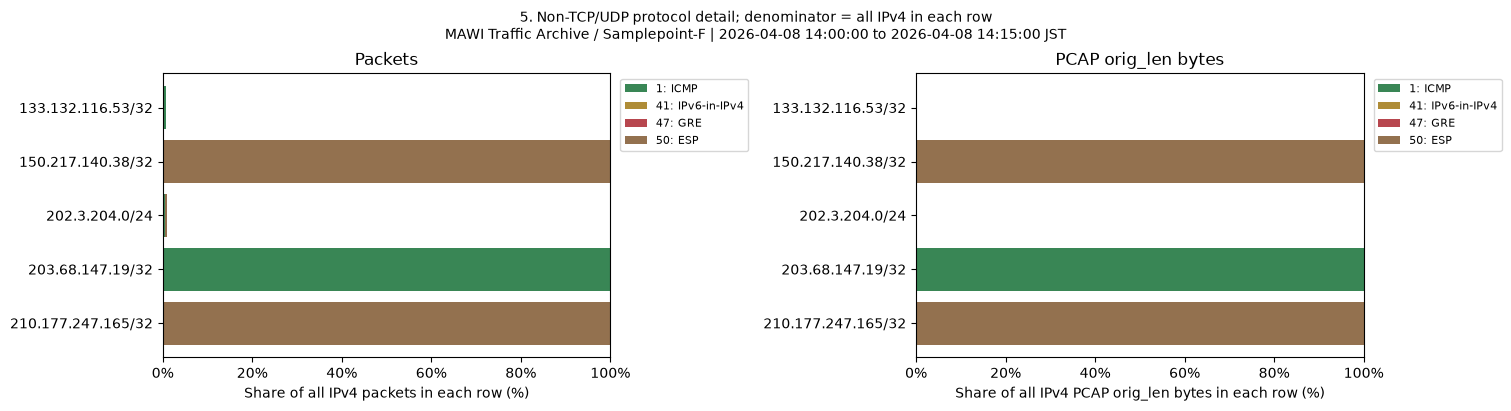

In [7]:
ranked = non_tcp_ratios["packet_count"].reindex(prefix_order).dropna().sort_values(ascending=False, kind="stable")
chosen = set(ranked.head(DETAIL_TOP_N).index)
detail_prefixes = [p for p in prefix_order if p in chosen]
detail_table = non_tcp.loc[non_tcp["scope"].isin(detail_prefixes), ["scope", "protocol_number", "protocol_name", *MEASURES]].copy()
for metric in ("packet_count", BYTE_METRIC):
    detail_table[f"{metric}_pct_of_all_ipv4"] = detail_table[metric].div(detail_table["scope"].map(totals[metric]).replace(0, np.nan)) * 100
display(detail_table)
fig, axes = plt.subplots(1, 2, figsize=(FIGSIZE[0] + 3, max(4, len(detail_prefixes) * .65)), layout="constrained")
for ax, metric, title in zip(axes, ("packet_count", BYTE_METRIC), ("Packets", byte_label)):
    detail_shares = percent(shown_values(metric, non_tcp), metric).loc[detail_prefixes]
    nonzero_columns = detail_shares.fillna(0).ne(0).any()
    detail_shares = detail_shares.loc[:, nonzero_columns]
    if detail_prefixes:
        stacked(ax, detail_shares, metric)
    else:
        ax.text(.5, .5, "No prefixes with a defined denominator", transform=ax.transAxes, ha="center")
        ax.set_yticks([])
    ax.set_title(title)
finish(fig, "5. Non-TCP/UDP protocol detail; denominator = all IPv4 in each row")
